In [18]:
import torch
from torch import nn
RANDOM_SEED = 42

In [19]:
from sklearn.datasets import make_moons
import pandas as pd 
import matplotlib.pyplot as plt

X, y = make_moons(
    1000,
    random_state=42,
    noise=0.03
)

df = pd.DataFrame(
    {'X1' : X[:, 0], 'X2' : X[:, 1], 'label':y}
)
df.head()

,X1,X2,label
0,-0.009332,0.390981,1
1,0.954574,-0.473756,1
2,0.918526,-0.425196,1
3,0.412768,-0.376385,1
4,-0.845320,0.528799,0


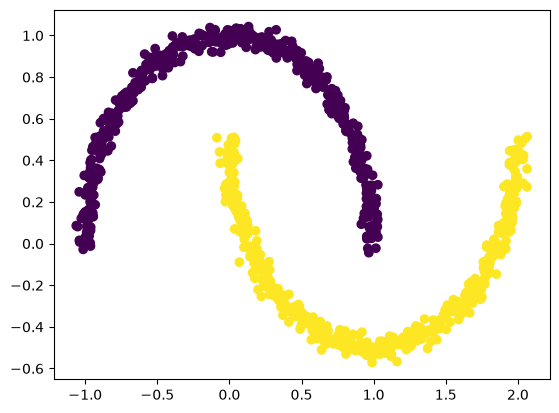

In [20]:
plt.scatter(x=X[:, 0], y=X[:, 1], c=y)

In [24]:
# Convert from NumPy arrays to PyTorch float tensors
X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)


In [28]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)
print(x_train.shape, y_train.shape, x_test.shape, y_test.shape)

torch.Size([800, 2]) torch.Size([800]) torch.Size([200, 2]) torch.Size([200])


In [45]:
class MoonModelV0(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(2,10),
            nn.ReLU(),
            nn.Linear(10,1)
            
        )
    def forward(self, x):
        return self.network(x)

modelV0 = MoonModelV0()
print(modelV0)

MoonModelV0(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=10, bias=True)
    (1): ReLU()
    (2): Linear(in_features=10, out_features=1, bias=True)
  )
)


In [100]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(
    params=modelV0.parameters(),
    lr = 0.1
)

epochs = 100
for epoch in range(epochs):
    modelV0.train()

    y_logits = modelV0(x_train).squeeze()
    y_preds = torch.round(torch.sigmoid(y_logits))

    loss = loss_fn(y_logits, y_train)
    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    modelV0.eval()
    with torch.inference_mode():
        test_logits = modelV0(x_test).squeeze()
        test_pred = torch.round(torch.sigmoid(test_logits))
        test_loss = loss_fn(test_logits, y_test)
    if epoch % 10 ==0:
        print(f"Epoch: {epoch}, Loss: {loss:.5f}, Test Loss: {test_loss:.5f}")

Epoch: 0, Loss: 0.18861, Test Loss: 0.21651
Epoch: 10, Loss: 0.19195, Test Loss: 0.18825
Epoch: 20, Loss: 0.17728, Test Loss: 0.16792
Epoch: 30, Loss: 0.11960, Test Loss: 0.10766
Epoch: 40, Loss: 0.04535, Test Loss: 0.03975
Epoch: 50, Loss: 0.01522, Test Loss: 0.01194
Epoch: 60, Loss: 0.00606, Test Loss: 0.00538
Epoch: 70, Loss: 0.00348, Test Loss: 0.00332
Epoch: 80, Loss: 0.00242, Test Loss: 0.00238
Epoch: 90, Loss: 0.00191, Test Loss: 0.00186


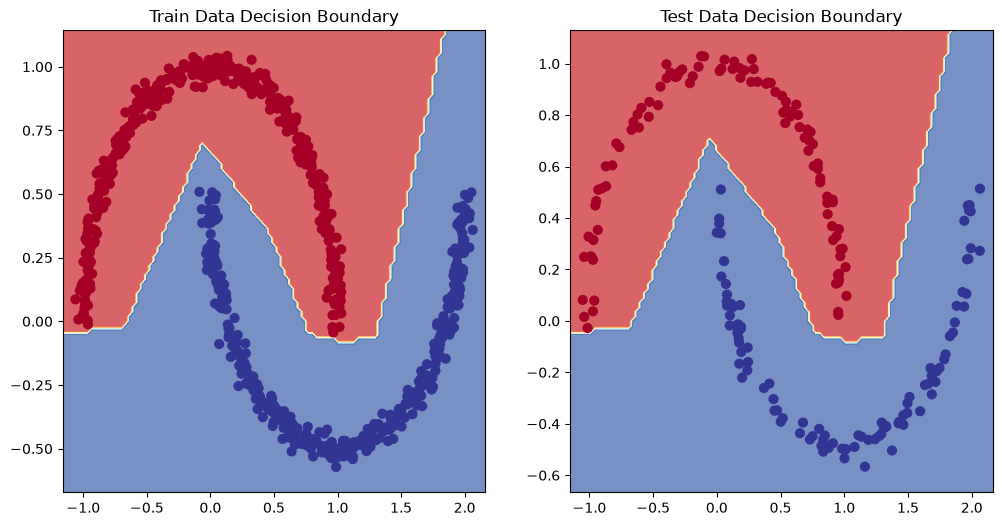

In [103]:
# Import the custom plotting function from your script
from helper_functions import plot_decision_boundary

# Plot the decision boundary for your test data
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train Data Decision Boundary")
plot_decision_boundary(modelV0, x_train, y_train)

plt.subplot(1, 2, 2)
plt.title("Test Data Decision Boundary")
plot_decision_boundary(modelV0, x_test, y_test)


In [108]:
import pandas as pd

# 1. Convert PyTorch tensors to NumPy arrays
# (We use .cpu() just in case they are on a GPU, and .numpy() to extract the data)
actual_labels = y_test.cpu().numpy()
predicted_labels = test_pred.cpu().numpy()

# 2. Create the Pandas DataFrame
comparison_df = pd.DataFrame({
    "Actual": actual_labels.astype(int),       # Cast to integer for clean 0s and 1s
    "Predicted": predicted_labels.astype(int)
})

# 3. Add a column to instantly see if the model got it right
comparison_df["Correct?"] = comparison_df["Actual"] == comparison_df["Predicted"]

# View the first 10 rows
comparison_df.head(10)


,Actual,Predicted,Correct?
0,1,1,True
1,0,0,True
2,1,1,True
3,0,0,True
4,1,1,True
5,1,1,True
6,0,0,True
7,0,0,True
8,1,1,True
9,0,0,True


In [109]:
# Show only the rows where the model guessed incorrectly
mistakes = comparison_df[comparison_df["Correct?"] == False]
print(f"Total mistakes: {len(mistakes)}")
mistakes


Total mistakes: 0


,Actual,Predicted,Correct?
